# DMER — Group GLHMM result evaluation

This notebook adapts the original **single-subject evaluation** to **one group-trained GLHMM** shared by all subjects. It keeps each video's trial boundary and evaluates subjects independently before testing emotion effects across subjects.

**Inputs:** one trained `GLHMM_Group_model.pkl` and one `DMER_GLHMM_features*.npz` per subject with `X`, `Y`, `indices`, and `video_ids`.

**Outputs:** individual subject state probabilities (cached), trial-level metrics, subject-by-emotion metrics, group plots, repeated-measures tests, and shared state-parameter plots.

Important:

- The **feature filename and group-model path must match the model you actually trained**. The original notebook used Theta-only features; this notebook defaults to **full-band (90 EEG features)**, in line with your latest group-training script. Change `feature_filename` to `DMER_GLHMM_features_Theta.npz` only if your **group model was trained on Theta**.
- EEG 4 s / GSR 5 s / PPG 8 s window lengths do **not** change the 1-second feature sampling interval.
- Emotion labels are inferred from video ID: **0–7 Positive, 8–15 Negative, 16–31 Mixed**.
- Do not mix subject-specific GLHMM states with these group states. State IDs are directly comparable **only because one group model is used for every subject**.


## 1. Configuration and shared model

Edit the two paths and the feature filename below. This notebook does **not retrain** the model, apply PCA, or standardize your already standardized features again.


In [65]:
import os
import re
import gc
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import friedmanchisquare, wilcoxon
from glhmm import io, utils

# =========================
# SETTINGS - EDIT THESE
# =========================

data_root = r"C:\Users\pipo\Datasets-Docs\Multimodal Dataset for Mixed Emotion Recognition\preprocessed_GLHMM"

# Must point to the SHARED group model, not subject_10/GLHMM_K4_noPCA_Theta.
group_model_dir = os.path.join(data_root, "GLHMM_Group_K4_noPCA_05sec")
group_model_file = "GLHMM_Group_model.pkl"

# Full-band = 90 EEG features; Theta-only = 18 EEG features.
# Choose the SAME feature files used when training this group model.
feature_filename = "DMER_GLHMM_features.npz"
# feature_filename = "DMER_GLHMM_features_Theta.npz"

step = 0.5                     # 1-second feature step (not window length)
first_feature_time = 8.0       # First feature endpoint, relative to aligned/trimmed segment
fs_features = 1.0 / step

save_subject_cache = True
subject_results_dir = os.path.join(group_model_dir, "Subject_Results")
analysis_dir = os.path.join(group_model_dir, "Group_Analysis")
os.makedirs(analysis_dir, exist_ok=True)
if save_subject_cache:
    os.makedirs(subject_results_dir, exist_ok=True)

# Accept either subject_10/ or 10/ subfolders.
subject_files = glob.glob(os.path.join(data_root, "*", feature_filename))

def subject_id_from_path(path):
    folder_name = Path(path).parent.name
    match = re.search(r"(\d+)$", folder_name)
    if match is None:
        raise ValueError(f"Cannot extract subject ID from folder: {folder_name}")
    return int(match.group(1))

subject_files = sorted(subject_files, key=subject_id_from_path)
if not subject_files:
    raise FileNotFoundError(
        f"No {feature_filename} files found one folder below {data_root}"
    )

subject_ids = [subject_id_from_path(f) for f in subject_files]
if len(subject_ids) != len(set(subject_ids)):
    raise ValueError("Duplicate subject IDs found. Please inspect your folders.")

hmm = io.load_hmm(group_model_file, directory=group_model_dir)
K = int(hmm.hyperparameters["K"])
betas = np.asarray(hmm.get_betas())

if betas.ndim != 3 or betas.shape[0] != 5 or betas.shape[2] != K:
    raise ValueError(f"Unexpected group-model beta shape: {betas.shape}")

q_eeg = betas.shape[1]
print("Subjects found:", len(subject_files))
print("Subject IDs:", subject_ids)
print("Group model states (K):", K)
print("Group model expects EEG features:", q_eeg)
print("Group model expects physiology features:", betas.shape[0])
print("Feature file:", feature_filename)


Subjects found: 71
Subject IDs: [1, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 18, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29, 30, 32, 33, 34, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80]
Group model states (K): 4
Group model expects EEG features: 90
Group model expects physiology features: 5
Feature file: DMER_GLHMM_features.npz


## 2. Per-trial and per-subject metrics

Decode **each subject using the same group model**. Your saved `indices` contain 32 video trials, so state inference restarts at each trial boundary.

- **FO**: fractional occupancy from posterior state probabilities (`Gamma`).
- **SR**: average absolute change in state probability between consecutive feature samples (not a literal count of discrete switches).
- **LTmean/LTmed/LTmax**: mean, median, and maximum durations of Viterbi state visits; converted from feature samples to **seconds** using `step`.

The output CSVs keep individual trials and also average trials **within each subject and emotion**. For the group statistical tests, the independent observations are subjects, not overlapping 1-second windows or 32 trials.


In [66]:
emotion_names = ["Positive", "Negative", "Mixed"]

def emotion_from_video(video_id):
    if 0 <= video_id <= 7:
        return "Positive"
    if 8 <= video_id <= 15:
        return "Negative"
    if 16 <= video_id <= 31:
        return "Mixed"
    raise ValueError(f"Unexpected video ID: {video_id}")

def get_trial_video_ids(video_ids, indices):
    trial_vids = []
    for start, end in indices:
        values = np.unique(video_ids[start:end])
        if len(values) != 1:
            raise ValueError(
                f"A trial contains {len(values)} different video IDs: {values}"
            )
        trial_vids.append(int(values[0]))
    return np.asarray(trial_vids, dtype=int)

def finite_mean(values):
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]
    return float(valid.mean()) if len(valid) else np.nan

trial_rows = []
subject_emotion_rows = []
qc_rows = []

for number, file_path in enumerate(subject_files, start=1):
    subject_id = subject_id_from_path(file_path)

    with np.load(file_path) as data:
        X_sub = np.asarray(data["X"])
        Y_sub = np.asarray(data["Y"])
        indices_sub = np.asarray(data["indices"], dtype=int)
        video_ids = np.asarray(data["video_ids"]).reshape(-1)

    # Validate data before decoding.
    if X_sub.ndim != 2 or X_sub.shape[1] != betas.shape[0]:
        raise ValueError(f"Subject {subject_id}: unexpected X shape {X_sub.shape}")
    if Y_sub.ndim != 2 or Y_sub.shape[1] != q_eeg:
        raise ValueError(
            f"Subject {subject_id}: EEG shape {Y_sub.shape} does not match "
            f"group model with {q_eeg} EEG features. Check feature_filename."
        )
    if len(X_sub) != len(Y_sub) or len(video_ids) != len(Y_sub):
        raise ValueError(f"Subject {subject_id}: X/Y/video_ids lengths differ")
    if indices_sub.shape != (32, 2):
        raise ValueError(f"Subject {subject_id}: expected (32,2) indices")
    if (indices_sub[0, 0] != 0 or indices_sub[-1, 1] != len(Y_sub)
            or not np.array_equal(indices_sub[1:, 0], indices_sub[:-1, 1])
            or np.any(indices_sub[:, 1] <= indices_sub[:, 0])):
        raise ValueError(f"Subject {subject_id}: invalid trial boundaries")
    if not np.isfinite(X_sub).all() or not np.isfinite(Y_sub).all():
        raise ValueError(f"Subject {subject_id}: nonfinite features")

    trial_video_ids = get_trial_video_ids(video_ids, indices_sub)
    if len(np.unique(trial_video_ids)) != 32:
        raise ValueError(f"Subject {subject_id}: expected 32 distinct videos")

    # Posterior probabilities (T, K) and one-hot Viterbi path (T, K).
    Gamma, _, _ = hmm.decode(
        X=X_sub, Y=Y_sub, indices=indices_sub,
        viterbi=False, serial=True
    )
    vpath = hmm.decode(
        X=X_sub, Y=Y_sub, indices=indices_sub,
        viterbi=True, serial=False  # avoids the serial=True Viterbi bug
    )

    FO = np.asarray(utils.get_FO(Gamma, indices_sub))
    SR = np.asarray(utils.get_switching_rate(Gamma, indices_sub))
    LTmean, LTmed, LTmax = utils.get_life_times(vpath, indices_sub)
    LTmean = np.asarray(LTmean, dtype=float) / fs_features
    LTmed = np.asarray(LTmed, dtype=float) / fs_features
    LTmax = np.asarray(LTmax, dtype=float) / fs_features

    if FO.shape != (32, K) or SR.shape != (32, K) or LTmean.shape != (32, K):
        raise ValueError(f"Subject {subject_id}: unexpected metric shapes")

    for trial_index, (start, end) in enumerate(indices_sub):
        video_id = trial_video_ids[trial_index]
        emotion = emotion_from_video(video_id)
        for state in range(K):
            trial_rows.append({
                "subject_id": subject_id,
                "trial_index": trial_index,
                "video_id": int(video_id),
                "emotion": emotion,
                "state": state + 1,
                "n_samples": int(end - start),
                "FO": FO[trial_index, state],
                "SR": SR[trial_index, state],
                "LTmean_s": LTmean[trial_index, state],
                "LTmed_s": LTmed[trial_index, state],
                "LTmax_s": LTmax[trial_index, state],
            })

    for emotion in emotion_names:
        trial_mask = np.array(
            [emotion_from_video(v) == emotion for v in trial_video_ids]
        )
        for state in range(K):
            subject_emotion_rows.append({
                "subject_id": subject_id,
                "emotion": emotion,
                "state": state + 1,
                "n_trials": int(trial_mask.sum()),
                "FO": finite_mean(FO[trial_mask, state]),
                "SR": finite_mean(SR[trial_mask, state]),
                "LTmean_s": finite_mean(LTmean[trial_mask, state]),
                "LTmed_s": finite_mean(LTmed[trial_mask, state]),
                "LTmax_s": finite_mean(LTmax[trial_mask, state]),
            })

    gamma_error = float(np.max(np.abs(Gamma.sum(axis=1) - 1.0)))
    qc_rows.append({
        "subject_id": subject_id,
        "n_samples": len(Y_sub),
        "n_trials": len(indices_sub),
        "max_gamma_sum_error": gamma_error,
        "min_state_occupancy": float(Gamma.mean(axis=0).min()),
        "n_states_over_1pct": int(np.sum(Gamma.mean(axis=0) > 0.01)),
    })

    # Cache the common group-model state IDs for single-subject plots.
    if save_subject_cache:
        out_path = os.path.join(
            subject_results_dir, f"Subject_{subject_id}_group_results.npz"
        )
        np.savez_compressed(
            out_path,
            Gamma=Gamma,
            vpath=vpath.astype(np.uint8),
            indices=indices_sub,
            trial_video_ids=trial_video_ids,
            FO=FO, SR=SR,
            LTmean=LTmean, LTmed=LTmed, LTmax=LTmax,
        )

    print(
        f"[{number:02d}/{len(subject_files)}] Subject {subject_id}: "
        f"{len(Y_sub)} samples, 32 trials, "
        f"Gamma error={gamma_error:.1e}"
    )

    # Memory is released before the next subject is loaded.
    del X_sub, Y_sub, indices_sub, video_ids, trial_video_ids
    del Gamma, vpath, FO, SR, LTmean, LTmed, LTmax
    gc.collect()


[01/71] Subject 1: 651 samples, 32 trials, Gamma error=2.2e-16


c:\Users\pipo\miniconda3\envs\glhmm\Lib\site-packages\glhmm\auxiliary.py:355: RuntimeWarning: invalid value encountered in divide
  delta[t,:,:] = delta[t,:,:] / np.expand_dims(np.sum(delta[t,:,:],axis=1),axis=1)


[02/71] Subject 5: 651 samples, 32 trials, Gamma error=2.2e-16
[03/71] Subject 6: 648 samples, 32 trials, Gamma error=2.2e-16
[04/71] Subject 7: 651 samples, 32 trials, Gamma error=2.2e-16
[05/71] Subject 8: 651 samples, 32 trials, Gamma error=2.2e-16
[06/71] Subject 9: 649 samples, 32 trials, Gamma error=2.2e-16
[07/71] Subject 10: 649 samples, 32 trials, Gamma error=2.2e-16
[08/71] Subject 11: 651 samples, 32 trials, Gamma error=2.2e-16
[09/71] Subject 12: 648 samples, 32 trials, Gamma error=2.2e-16
[10/71] Subject 14: 651 samples, 32 trials, Gamma error=2.2e-16
[11/71] Subject 15: 649 samples, 32 trials, Gamma error=2.2e-16
[12/71] Subject 18: 650 samples, 32 trials, Gamma error=2.2e-16
[13/71] Subject 19: 651 samples, 32 trials, Gamma error=2.2e-16
[14/71] Subject 20: 650 samples, 32 trials, Gamma error=2.2e-16
[15/71] Subject 21: 648 samples, 32 trials, Gamma error=2.2e-16
[16/71] Subject 22: 651 samples, 32 trials, Gamma error=2.2e-16
[17/71] Subject 23: 651 samples, 32 trials, G

## 3. Combine the results into group-level tables

`trial_metrics.csv` contains **32 trials × K states × N subjects**. `subject_emotion_metrics.csv` contains **3 emotion conditions × K states × N subjects**, with each subject counted once per condition. The latter is appropriate for group statistics, even though the Mixed condition contains 16 trials and Positive/Negative contain 8 each.


In [67]:
trial_df = pd.DataFrame(trial_rows)
subject_df = pd.DataFrame(subject_emotion_rows)
qc_df = pd.DataFrame(qc_rows)

trial_df.to_csv(os.path.join(analysis_dir, "trial_metrics.csv"), index=False)
subject_df.to_csv(os.path.join(analysis_dir, "subject_emotion_metrics.csv"), index=False)
qc_df.to_csv(os.path.join(analysis_dir, "subject_qc.csv"), index=False)

print("Trial-level rows:", len(trial_df))
print("Subject × emotion rows:", len(subject_df))
print("Subject QC rows:", len(qc_df))
print("Subjects per emotion:")
print(subject_df.groupby("emotion")["subject_id"].nunique().reindex(emotion_names))
print("\nSubject QC:")
display(qc_df.head())
print("\nSubject/emotion metrics:")
display(subject_df.head(12))

# Group means: each subject contributes one value per emotion and state.
group_summary = (
    subject_df.groupby(["emotion", "state"], as_index=False)
    .agg(
        n_subjects=("subject_id", "nunique"),
        FO_mean=("FO", "mean"),
        FO_sd=("FO", "std"),
        SR_mean=("SR", "mean"),
        SR_sd=("SR", "std"),
        LTmean_s_mean=("LTmean_s", "mean"),
        LTmean_s_sd=("LTmean_s", "std"),
    )
)
group_summary.to_csv(os.path.join(analysis_dir, "group_summary.csv"), index=False)
display(group_summary)


Trial-level rows: 9088
Subject × emotion rows: 852
Subject QC rows: 71
Subjects per emotion:
emotion
Positive    71
Negative    71
Mixed       71
Name: subject_id, dtype: int64

Subject QC:


,subject_id,n_samples,n_trials,max_gamma_sum_error,min_state_occupancy,n_states_over_1pct
0,1,651,32,2.220446e-16,0.039960,4
1,5,651,32,2.220446e-16,0.049353,4
2,6,648,32,2.220446e-16,0.053457,4
3,7,651,32,2.220446e-16,0.058944,4
4,8,651,32,2.220446e-16,0.027493,4



Subject/emotion metrics:


,subject_id,emotion,state,n_trials,FO,SR,LTmean_s,LTmed_s,LTmax_s
0,1,Positive,1,8,0.084215,0.112390,0.625000,0.625000,0.62500
1,1,Positive,2,8,0.429493,0.339534,1.319792,1.187500,2.25000
2,1,Positive,3,8,0.045002,0.082835,0.375000,0.375000,0.37500
3,1,Positive,4,8,0.441290,0.259825,1.625000,1.312500,2.87500
4,1,Negative,1,8,0.035291,0.034678,0.375000,0.375000,0.37500
5,1,Negative,2,8,0.364479,0.296583,1.182292,1.031250,2.00000
6,1,Negative,3,8,0.105951,0.197364,0.416667,0.375000,0.50000
7,1,Negative,4,8,0.494279,0.358045,1.377083,1.250000,2.31250
8,1,Mixed,1,16,0.016310,0.028009,0.187500,0.187500,0.18750
9,1,Mixed,2,16,0.424921,0.316827,1.239063,1.187500,2.00000


,emotion,state,n_subjects,FO_mean,FO_sd,SR_mean,SR_sd,LTmean_s_mean,LTmean_s_sd
0,Mixed,1,71,0.060328,0.032878,0.046922,0.028660,0.451658,0.221391
1,Mixed,2,71,0.320901,0.129657,0.226852,0.095043,1.351218,1.053849
2,Mixed,3,71,0.309221,0.263047,0.178450,0.091479,1.619527,1.812382
3,Mixed,4,71,0.309551,0.165097,0.219568,0.128300,1.220197,0.746839
4,Negative,1,71,0.057319,0.043058,0.047998,0.034096,0.396494,0.269387
5,Negative,2,71,0.300704,0.147147,0.231773,0.098807,1.206751,1.142740
6,Negative,3,71,0.311598,0.269283,0.178852,0.098257,1.574589,1.716041
7,Negative,4,71,0.330379,0.189413,0.229186,0.132324,1.229624,0.908802
8,Positive,1,71,0.064946,0.057783,0.046170,0.032613,0.511810,0.428768
9,Positive,2,71,0.324679,0.151403,0.236410,0.097671,1.392589,1.412449


In [68]:
trial_df.columns

Index(['subject_id', 'trial_index', 'video_id', 'emotion', 'state',
       'n_samples', 'FO', 'SR', 'LTmean_s', 'LTmed_s', 'LTmax_s'],
      dtype='str')

## 4. Group emotion plots

Adapted from the original stacked FO and grouped SR/lifetime plots. Now each bar summarizes **subject-level emotion means**; error bars are **between-subject SEM**. A state color has the same meaning for every subject because all subjects were decoded with the same group model.


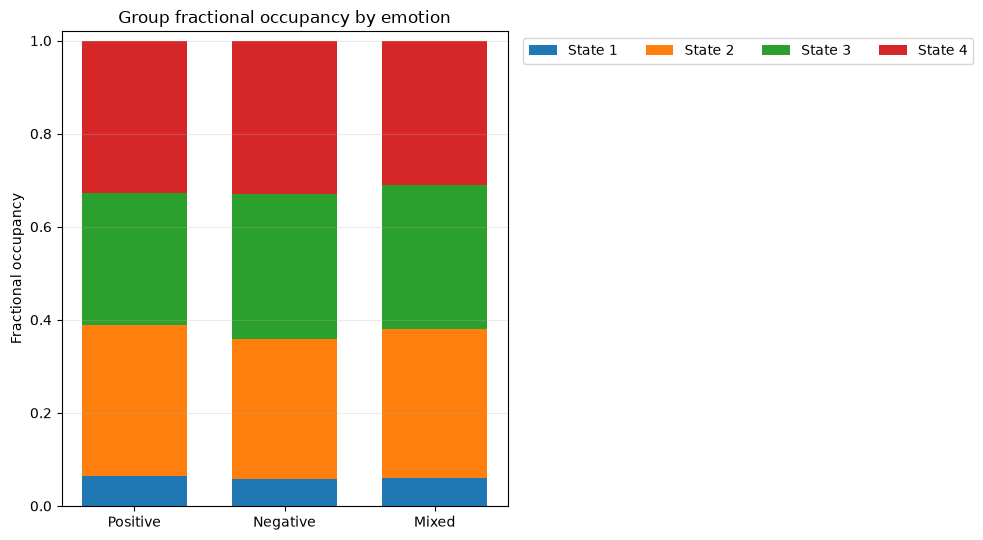

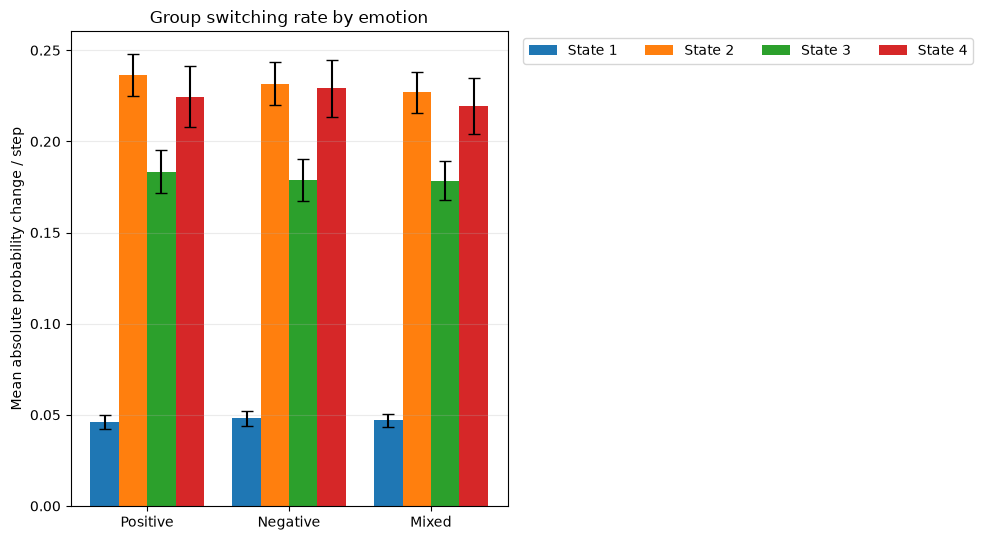

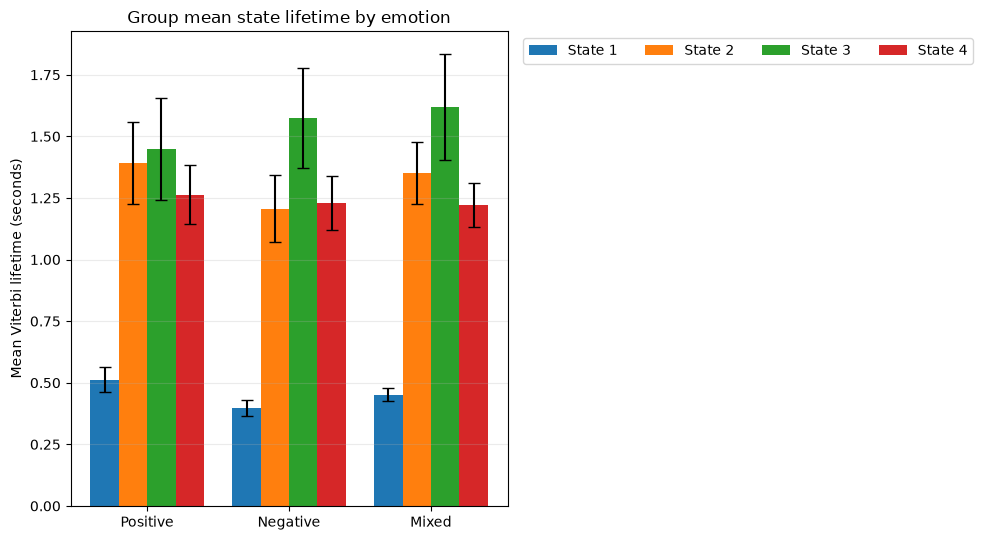

In [69]:
state_colors = plt.cm.tab10.colors[:K]

def plot_group_metric(metric_name, title, ylabel, stacked=False):
    means = np.full((len(emotion_names), K), np.nan)
    sems = np.full_like(means, np.nan)

    for e, emotion in enumerate(emotion_names):
        for state in range(1, K + 1):
            vals = subject_df.loc[
                (subject_df["emotion"] == emotion) &
                (subject_df["state"] == state), metric_name
            ].to_numpy(dtype=float)
            vals = vals[np.isfinite(vals)]
            if len(vals):
                means[e, state - 1] = vals.mean()
                sems[e, state - 1] = (
                    vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else np.nan
                )

    fig, ax = plt.subplots(figsize=(10, 5.5))
    x = np.arange(len(emotion_names))

    if stacked:
        bottom = np.zeros(len(emotion_names))
        for k in range(K):
            ax.bar(
                x, means[:, k], bottom=bottom,
                color=state_colors[k], label=f"State {k + 1}", width=0.7
            )
            bottom += means[:, k]
        ax.set_ylim(0, 1.02)
    else:
        width = 0.8 / K
        for k in range(K):
            ax.bar(
                x + (k - (K - 1) / 2) * width,
                means[:, k], width,
                yerr=sems[:, k], capsize=4,
                color=state_colors[k], label=f"State {k + 1}"
            )

    ax.set_xticks(x, emotion_names)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(ncol=min(K, 4), loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.tight_layout()
    plt.show()

plot_group_metric("FO", "Group fractional occupancy by emotion", "Fractional occupancy", stacked=True)
plot_group_metric("SR", "Group switching rate by emotion", "Mean absolute probability change / step")
plot_group_metric("LTmean_s", "Group mean state lifetime by emotion", "Mean Viterbi lifetime (seconds)")


### Subject-level distributions (one point per subject)

These plots help distinguish a group effect from a few outlier subjects. They also show the spread hidden by group-average bars.


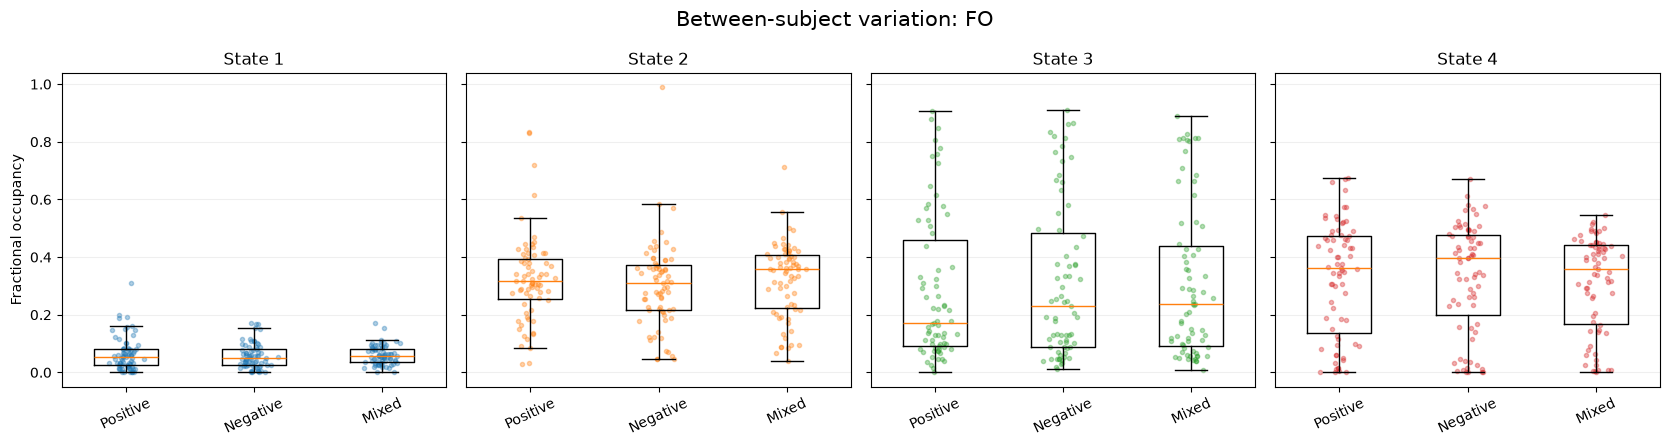

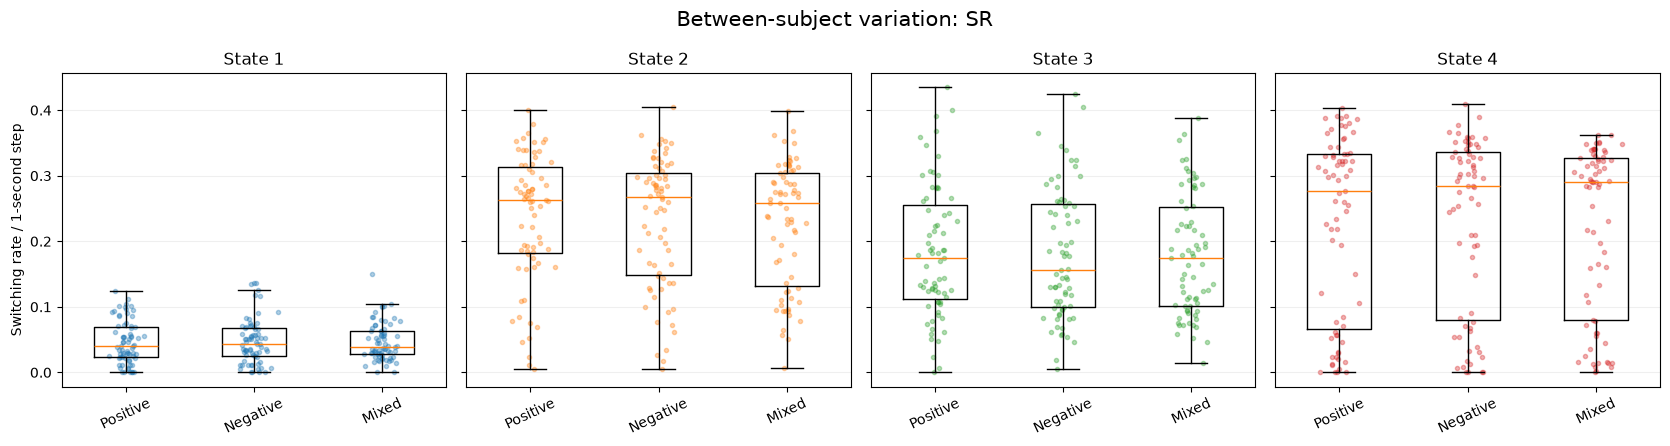

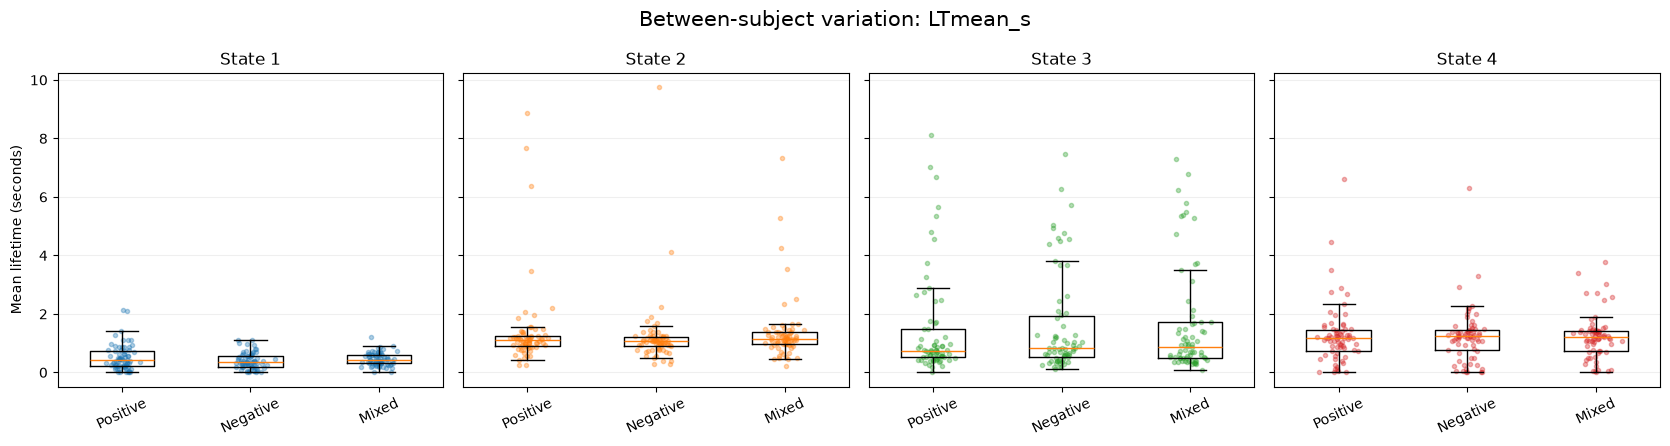

In [70]:
def plot_subject_distributions(metric_name, ylabel):
    fig, axes = plt.subplots(1, K, figsize=(4.2 * K, 4.5), sharey=True)
    axes = np.atleast_1d(axes)
    rng = np.random.default_rng(42)

    for k, ax in enumerate(axes):
        groups = []
        for emotion in emotion_names:
            vals = subject_df.loc[
                (subject_df["emotion"] == emotion) &
                (subject_df["state"] == k + 1), metric_name
            ].to_numpy(dtype=float)
            groups.append(vals[np.isfinite(vals)])

        ax.boxplot(groups, positions=np.arange(1, 4), widths=0.5, showfliers=False)
        for x, values in enumerate(groups, start=1):
            ax.scatter(
                x + rng.normal(0, 0.065, size=len(values)), values,
                s=9, color=state_colors[k], alpha=0.35
            )

        ax.set_xticks([1, 2, 3], emotion_names, rotation=25)
        ax.set_title(f"State {k + 1}")
        ax.grid(axis="y", alpha=0.2)

    axes[0].set_ylabel(ylabel)
    fig.suptitle(f"Between-subject variation: {metric_name}", fontsize=15)
    fig.tight_layout()
    plt.show()

plot_subject_distributions("FO", "Fractional occupancy")
plot_subject_distributions("SR", "Switching rate / 1-second step")
plot_subject_distributions("LTmean_s", "Mean lifetime (seconds)")


## 5. Repeated-measures emotion tests (exploratory)

Each subject experienced all three emotion categories. Use a **Friedman repeated-measures test** separately for each state and metric, with **Holm correction across the K × 3 omnibus tests**. A missing lifetime (the Viterbi path never entered a state) is treated as missing rather than zero. The number of complete subjects is shown in the output.

These comparisons test emotion differences, **not whether a model predicts emotion on held-out subjects**. Video identity and stimulus properties can contribute to the differences.


In [71]:
test_rows = []
metrics_to_test = ["FO", "SR", "LTmean_s"]

for metric_name in metrics_to_test:
    for state in range(1, K + 1):
        wide = (
            subject_df.loc[subject_df["state"] == state]
            .pivot(index="subject_id", columns="emotion", values=metric_name)
            .reindex(columns=emotion_names)
            .dropna()
        )
        if len(wide) < 3:
            stat, p_value = np.nan, np.nan
        else:
            stat, p_value = friedmanchisquare(
                wide["Positive"].values,
                wide["Negative"].values,
                wide["Mixed"].values,
            )
        test_rows.append({
            "metric": metric_name,
            "state": state,
            "n_complete_subjects": len(wide),
            "friedman_statistic": stat,
            "p_uncorrected": p_value,
        })

friedman_df = pd.DataFrame(test_rows)

# Holm family-wise correction without an extra library dependency.
p_values = friedman_df["p_uncorrected"].to_numpy(dtype=float)
finite = np.isfinite(p_values)
p_holm = np.full(len(p_values), np.nan)
if finite.any():
    raw = p_values[finite]
    order = np.argsort(raw)
    adjusted_sorted = np.minimum(
        1.0,
        np.maximum.accumulate((len(raw) - np.arange(len(raw))) * raw[order])
    )
    adjusted = np.empty_like(raw)
    adjusted[order] = adjusted_sorted
    p_holm[finite] = adjusted

friedman_df["p_holm"] = p_holm
friedman_df.to_csv(os.path.join(analysis_dir, "friedman_emotion_tests.csv"), index=False)
display(friedman_df)


,metric,state,n_complete_subjects,friedman_statistic,p_uncorrected,p_holm
0,FO,1,71,6.450704,0.039742,0.476901
1,FO,2,71,0.704225,0.703201,1.000000
2,FO,3,71,0.450704,0.798235,1.000000
3,FO,4,71,1.380282,0.501505,1.000000
4,SR,1,71,0.028169,0.986014,1.000000
5,SR,2,71,0.873239,0.646217,1.000000
6,SR,3,71,1.605634,0.448065,1.000000
7,SR,4,71,2.140845,0.342864,1.000000
8,LTmean_s,1,71,3.494585,0.174245,1.000000
9,LTmean_s,2,71,3.272085,0.194749,1.000000


### Optional paired post-hoc comparisons

If an omnibus test suggests an emotion difference, use paired Wilcoxon comparisons. Here they are reported exploratorily and Holm-adjusted together over all tested state/metric/emotion pairs. Interpret alongside the size and direction of the subject-level differences.


In [72]:
pairs = [("Positive", "Negative"), ("Positive", "Mixed"), ("Negative", "Mixed")]
pairwise_rows = []

for metric_name in metrics_to_test:
    for state in range(1, K + 1):
        wide = (
            subject_df.loc[subject_df["state"] == state]
            .pivot(index="subject_id", columns="emotion", values=metric_name)
        )
        for emotion_a, emotion_b in pairs:
            values = wide[[emotion_a, emotion_b]].dropna()
            difference = values[emotion_a].to_numpy() - values[emotion_b].to_numpy()
            if len(difference) < 3 or np.allclose(difference, 0):
                p_value = np.nan
            else:
                p_value = wilcoxon(difference).pvalue
            pairwise_rows.append({
                "metric": metric_name,
                "state": state,
                "comparison": f"{emotion_a} vs {emotion_b}",
                "n_paired_subjects": len(difference),
                "median_difference_A_minus_B": float(np.median(difference)) if len(difference) else np.nan,
                "p_uncorrected": p_value,
            })

pairwise_df = pd.DataFrame(pairwise_rows)
raw_p = pairwise_df["p_uncorrected"].to_numpy(dtype=float)
finite = np.isfinite(raw_p)
corrected = np.full(len(raw_p), np.nan)
if finite.any():
    raw = raw_p[finite]
    order = np.argsort(raw)
    adjusted_sorted = np.minimum(
        1.0,
        np.maximum.accumulate((len(raw) - np.arange(len(raw))) * raw[order])
    )
    adjusted = np.empty_like(raw)
    adjusted[order] = adjusted_sorted
    corrected[finite] = adjusted
pairwise_df["p_holm"] = corrected

pairwise_df.to_csv(os.path.join(analysis_dir, "wilcoxon_pairwise_emotion_tests.csv"), index=False)
display(pairwise_df)


,metric,state,comparison,n_paired_subjects,median_difference_A_minus_B,p_uncorrected,p_holm
0,FO,1,Positive vs Negative,71,5.527483e-03,0.663223,1.0
1,FO,1,Positive vs Mixed,71,-8.794750e-03,0.626233,1.0
2,FO,1,Negative vs Mixed,71,-7.070734e-03,0.297027,1.0
3,FO,2,Positive vs Negative,71,1.131281e-02,0.338627,1.0
4,FO,2,Positive vs Mixed,71,-5.053497e-03,0.981715,1.0
5,FO,2,Negative vs Mixed,71,-8.760421e-03,0.120474,1.0
6,FO,3,Positive vs Negative,71,-2.017895e-03,0.347375,1.0
7,FO,3,Positive vs Mixed,71,-1.293991e-02,0.067577,1.0
8,FO,3,Negative vs Mixed,71,-1.264403e-03,0.726699,1.0
9,FO,4,Positive vs Negative,71,1.301044e-08,0.940622,1.0


## 6. Your original 4-trials-per-emotion plots — now using the group model

Choose a subject and plot four video trials in one figure for each emotion category, exactly as in your previous notebook. The key difference is that the `Gamma` values now come from the **shared group model**.


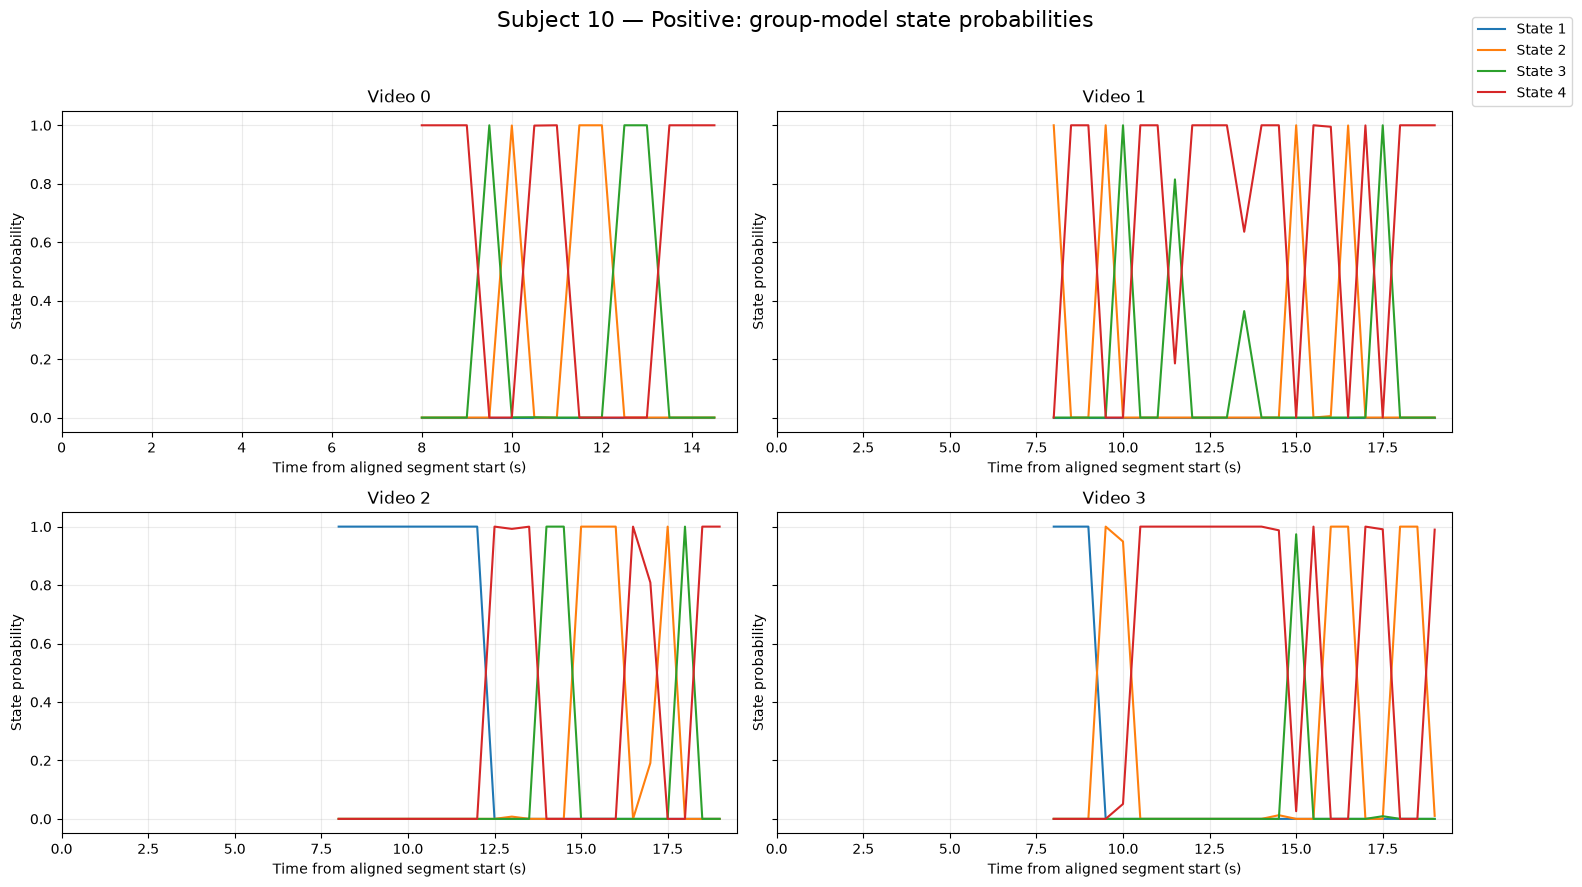

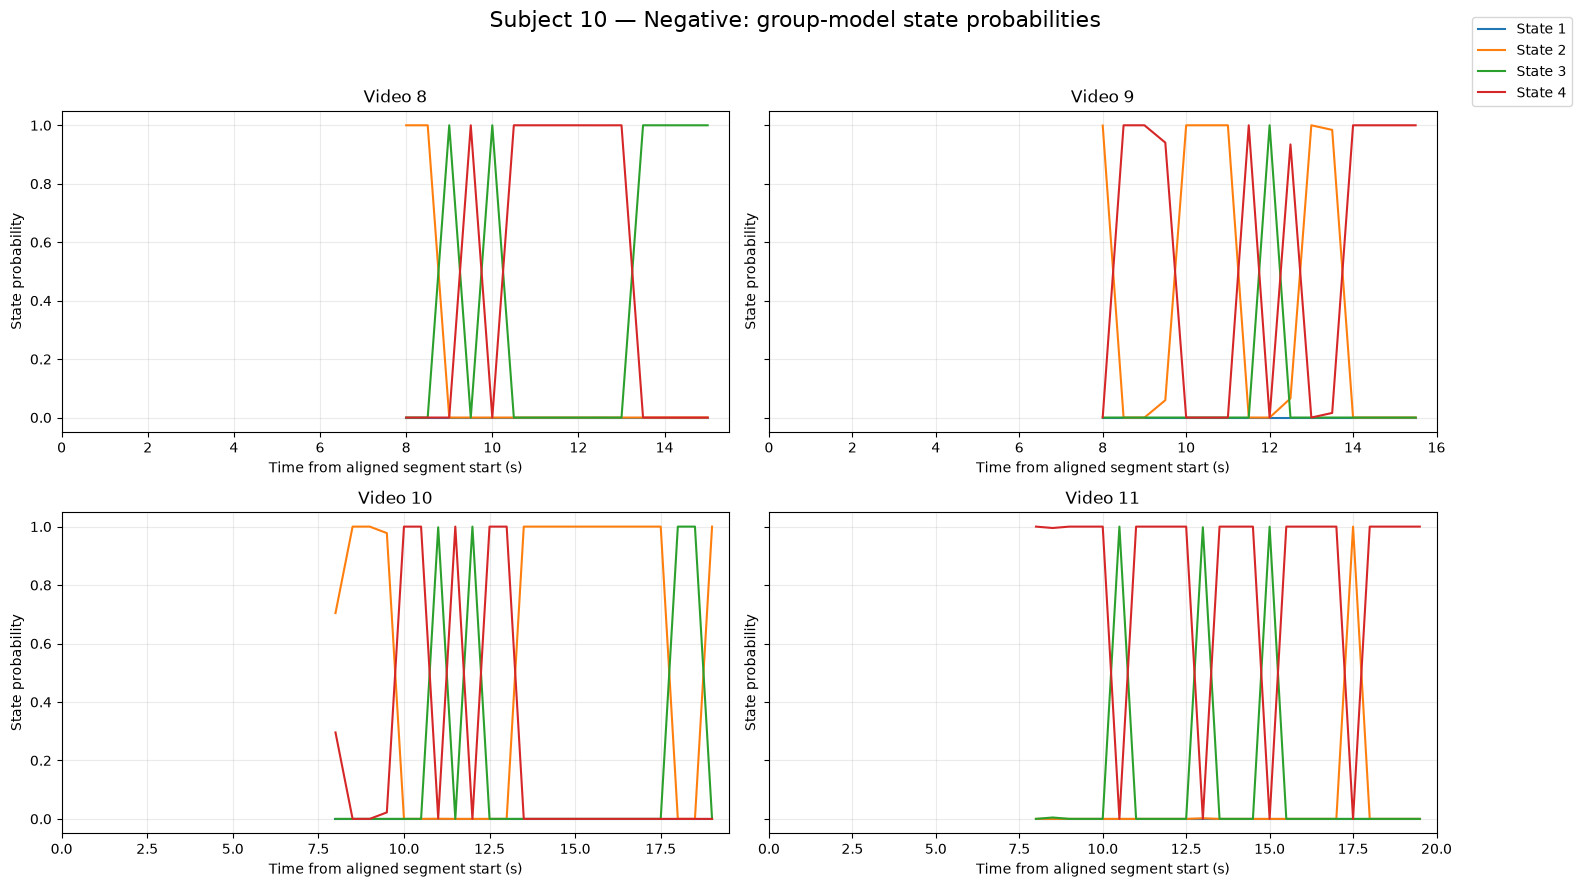

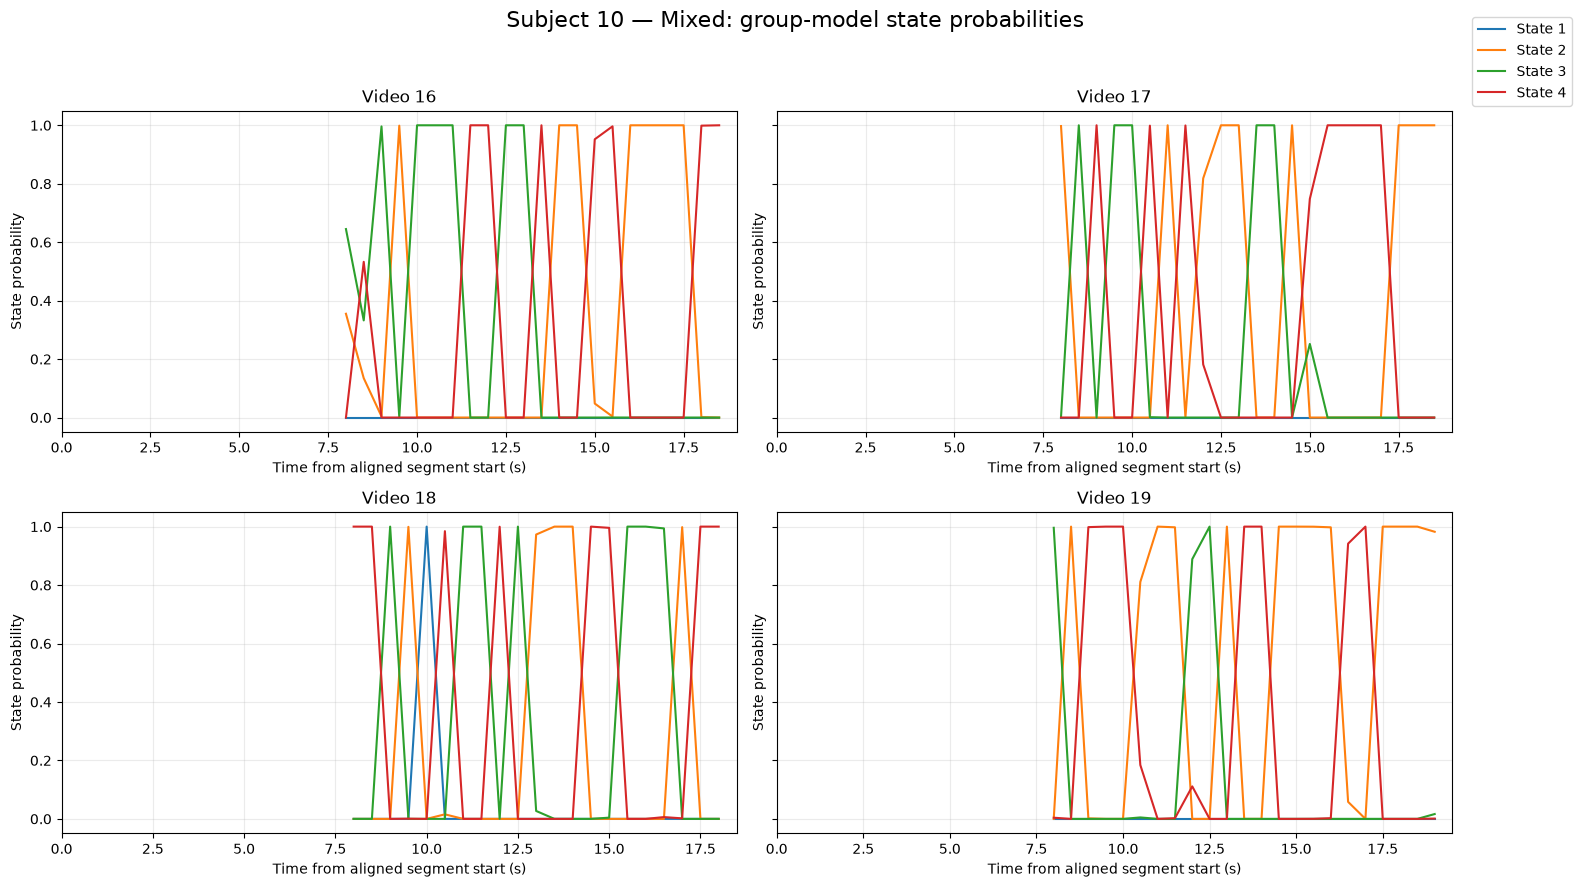

In [73]:
selected_subject = 10  # Change this to any subject ID in subject_ids.

selected_file = next(
    (f for f in subject_files if subject_id_from_path(f) == selected_subject),
    None
)
if selected_file is None:
    raise ValueError(f"Subject {selected_subject} not found. Available: {subject_ids}")

cached_path = os.path.join(
    subject_results_dir, f"Subject_{selected_subject}_group_results.npz"
)

if save_subject_cache and os.path.exists(cached_path):
    with np.load(cached_path) as data:
        Gamma_subject = data["Gamma"]
        indices_subject = data["indices"]
        trial_video_ids = data["trial_video_ids"]
        FO_subject = data["FO"]
        SR_subject = data["SR"]
        LTmean_subject = data["LTmean"]
else:
    with np.load(selected_file) as data:
        X_subject = data["X"]
        Y_subject = data["Y"]
        indices_subject = data["indices"].astype(int)
        video_ids_subject = data["video_ids"].reshape(-1)
    Gamma_subject, _, _ = hmm.decode(
        X=X_subject, Y=Y_subject, indices=indices_subject,
        viterbi=False, serial=True
    )
    vpath_subject = hmm.decode(
        X=X_subject, Y=Y_subject, indices=indices_subject,
        viterbi=True, serial=False
    )
    FO_subject = utils.get_FO(Gamma_subject, indices_subject)
    SR_subject = utils.get_switching_rate(Gamma_subject, indices_subject)
    LTmean_subject = utils.get_life_times(vpath_subject, indices_subject)[0] / fs_features
    trial_video_ids = get_trial_video_ids(video_ids_subject, indices_subject)

emotion_trials = {
    "Positive": [0, 1, 2, 3],
    "Negative": [8, 9, 10, 11],
    "Mixed": [16, 17, 18, 19],
}

for emotion, selected_videos in emotion_trials.items():
    fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)

    for ax, video_id in zip(axes.flat, selected_videos):
        trial_idx = np.flatnonzero(trial_video_ids == video_id)
        if len(trial_idx) != 1:
            raise ValueError(f"Expected exactly one trial for video {video_id}")
        start, end = indices_subject[trial_idx[0]]
        gamma_trial = Gamma_subject[start:end]

        # Time is relative to the aligned/trimmed segment, not necessarily the
        # original video onset (we cropped each modality to the common end).
        times = first_feature_time + np.arange(len(gamma_trial)) * step
        for state in range(K):
            ax.plot(
                times, gamma_trial[:, state], linewidth=1.5,
                color=state_colors[state], label=f"State {state + 1}"
            )
        ax.set_title(f"Video {video_id}")
        ax.set_ylim(-0.05, 1.05)
        ax.set_xlim(0, times[-1] + step)
        ax.grid(alpha=0.25)
        ax.set_xlabel("Time from aligned segment start (s)")
        ax.set_ylabel("State probability")

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.99, 0.98))
    fig.suptitle(
        f"Subject {selected_subject} — {emotion}: group-model state probabilities",
        fontsize=16
    )
    fig.tight_layout(rect=(0, 0, 0.92, 0.95))
    plt.show()


## 7. Original subject plots, adapted to group-state IDs

For the selected subject, retain the original trial-by-video stacked FO, SR, and mean-lifetime figures. These plots are descriptive and should not be used to calculate group-level p-values from individual trials.


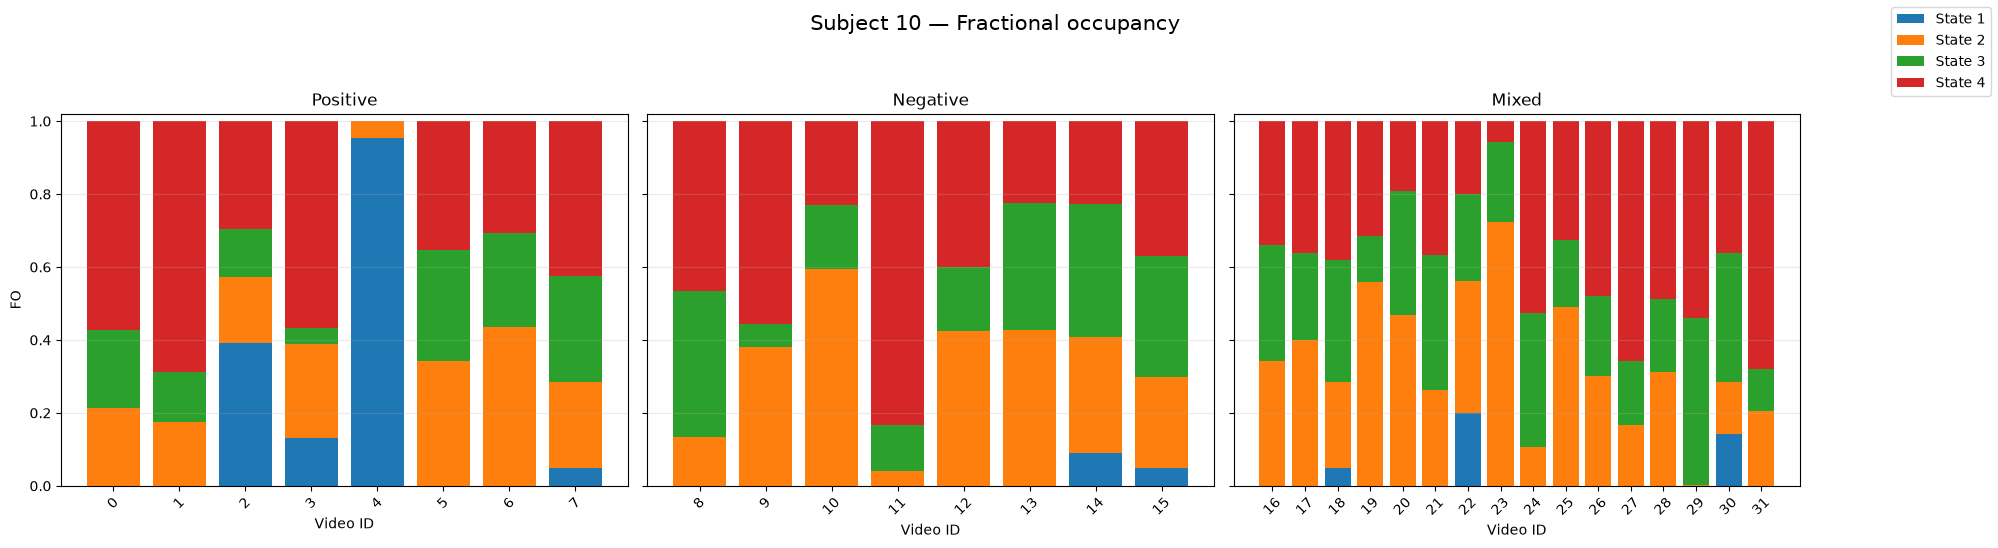

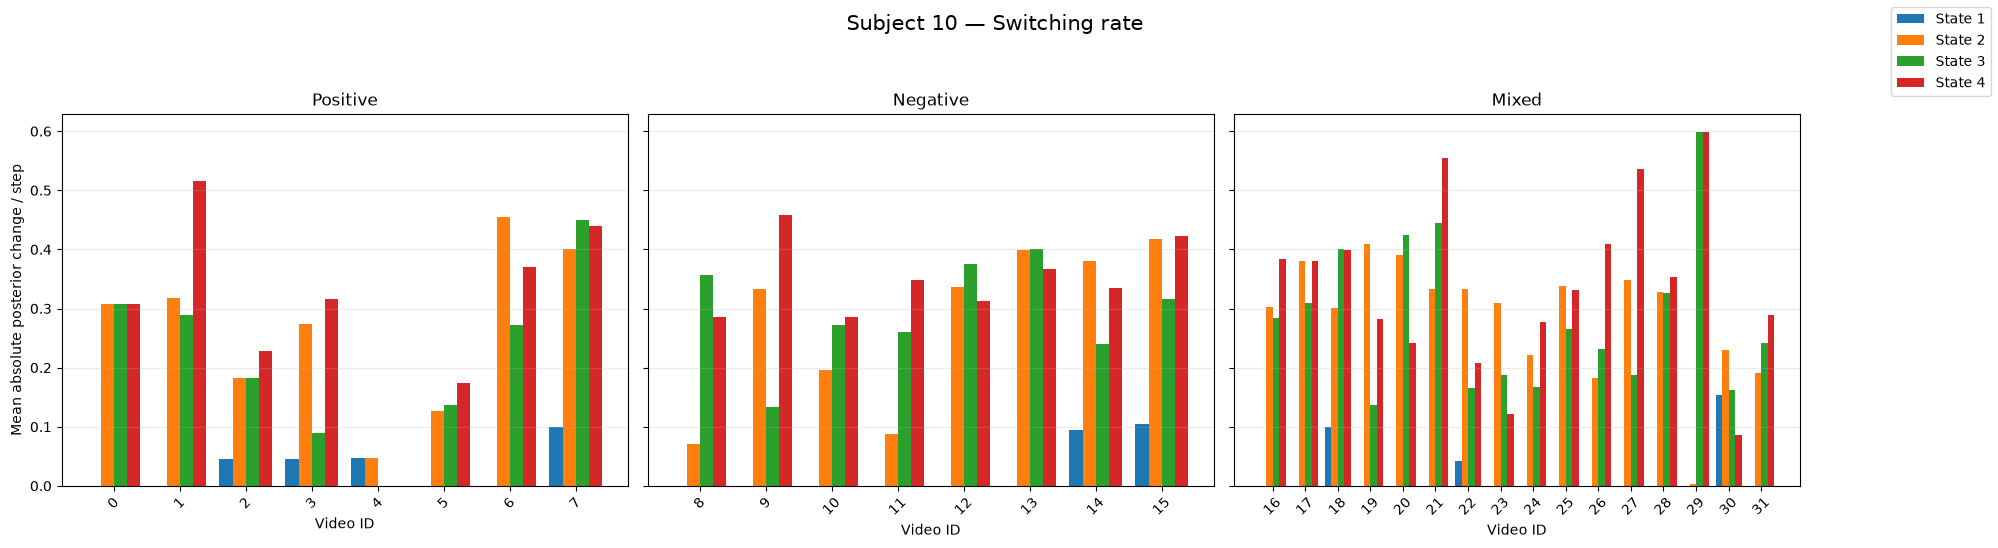

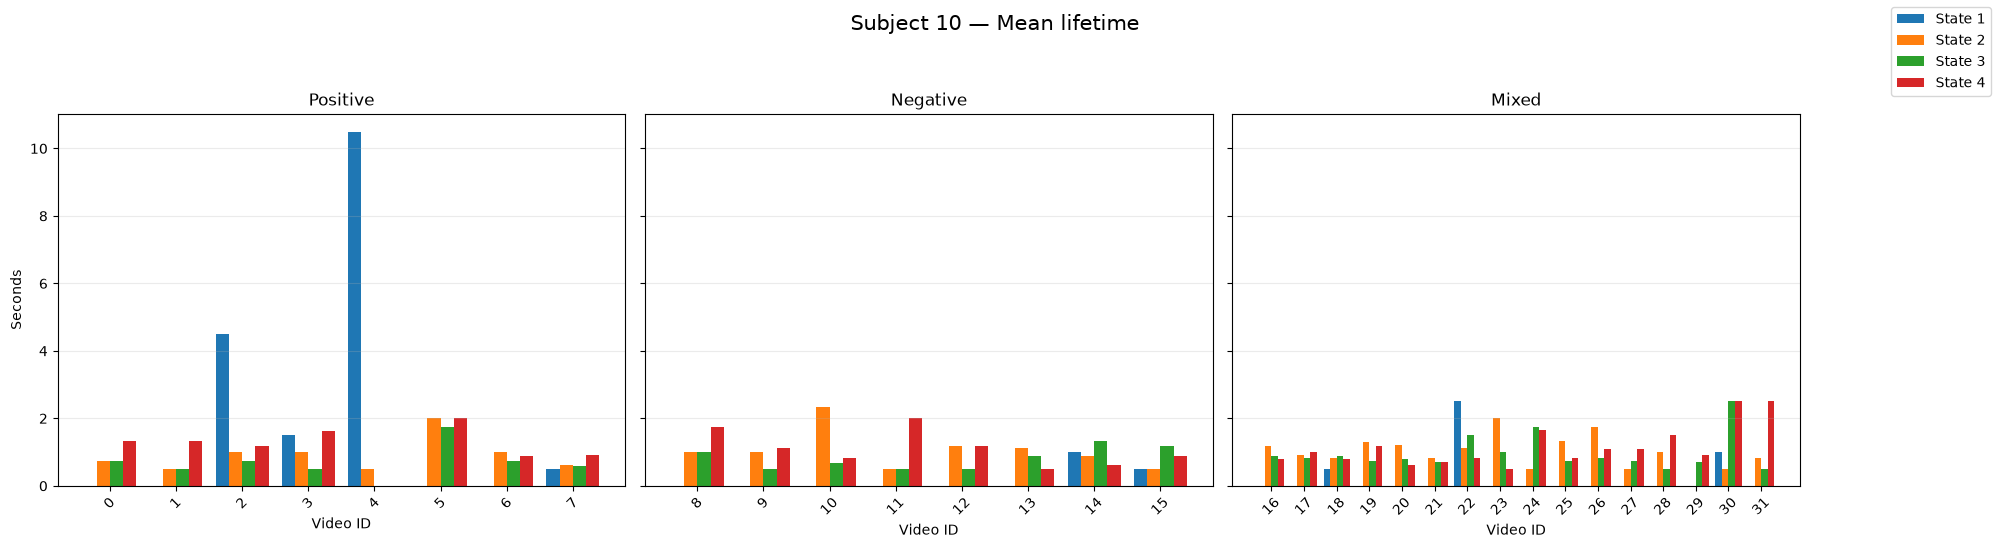

In [74]:
def plot_subject_metric(metric, title, ylabel, stacked=False):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
    for ax, emotion in zip(axes, emotion_names):
        trial_idx = np.flatnonzero(
            [emotion_from_video(v) == emotion for v in trial_video_ids]
        )
        values = metric[trial_idx, :]
        x = np.arange(len(trial_idx))

        if stacked:
            bottom = np.zeros(len(trial_idx))
            for k in range(K):
                ax.bar(
                    x, values[:, k], bottom=bottom,
                    color=state_colors[k], label=f"State {k + 1}"
                )
                bottom += values[:, k]
            ax.set_ylim(0, 1.02)
        else:
            width = 0.8 / K
            for k in range(K):
                ax.bar(
                    x + (k - (K - 1) / 2) * width,
                    values[:, k], width=width,
                    color=state_colors[k], label=f"State {k + 1}"
                )

        ax.set_xticks(x, trial_video_ids[trial_idx], rotation=45)
        ax.set_title(emotion)
        ax.set_xlabel("Video ID")
        ax.grid(axis="y", alpha=0.25)

    axes[0].set_ylabel(ylabel)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")
    fig.suptitle(f"Subject {selected_subject} — {title}", fontsize=15)
    fig.tight_layout(rect=(0, 0, 0.91, 0.93))
    plt.show()

plot_subject_metric(FO_subject, "Fractional occupancy", "FO", stacked=True)
plot_subject_metric(SR_subject, "Switching rate", "Mean absolute posterior change / step")
plot_subject_metric(LTmean_subject, "Mean lifetime", "Seconds")


## 8. Group-model state interpretations: EEG mean, EEG variance, and physiology→EEG beta

Unlike the original notebook, these parameters come from the **single group model** and are identical when you inspect any subject. For a diagonal covariance model, the variance plot shows **feature variances**, not EEG connectivity. Beta coefficients express **state-dependent associations** between standardized physiology and EEG features; they are not causal effects and are not emotion-specific model parameters.


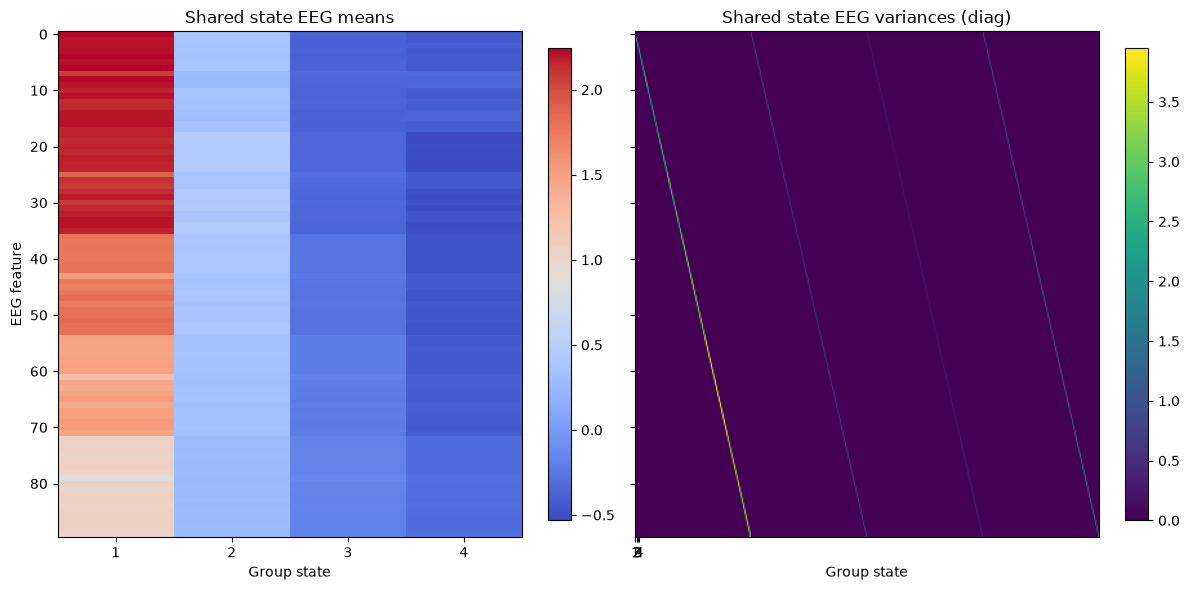

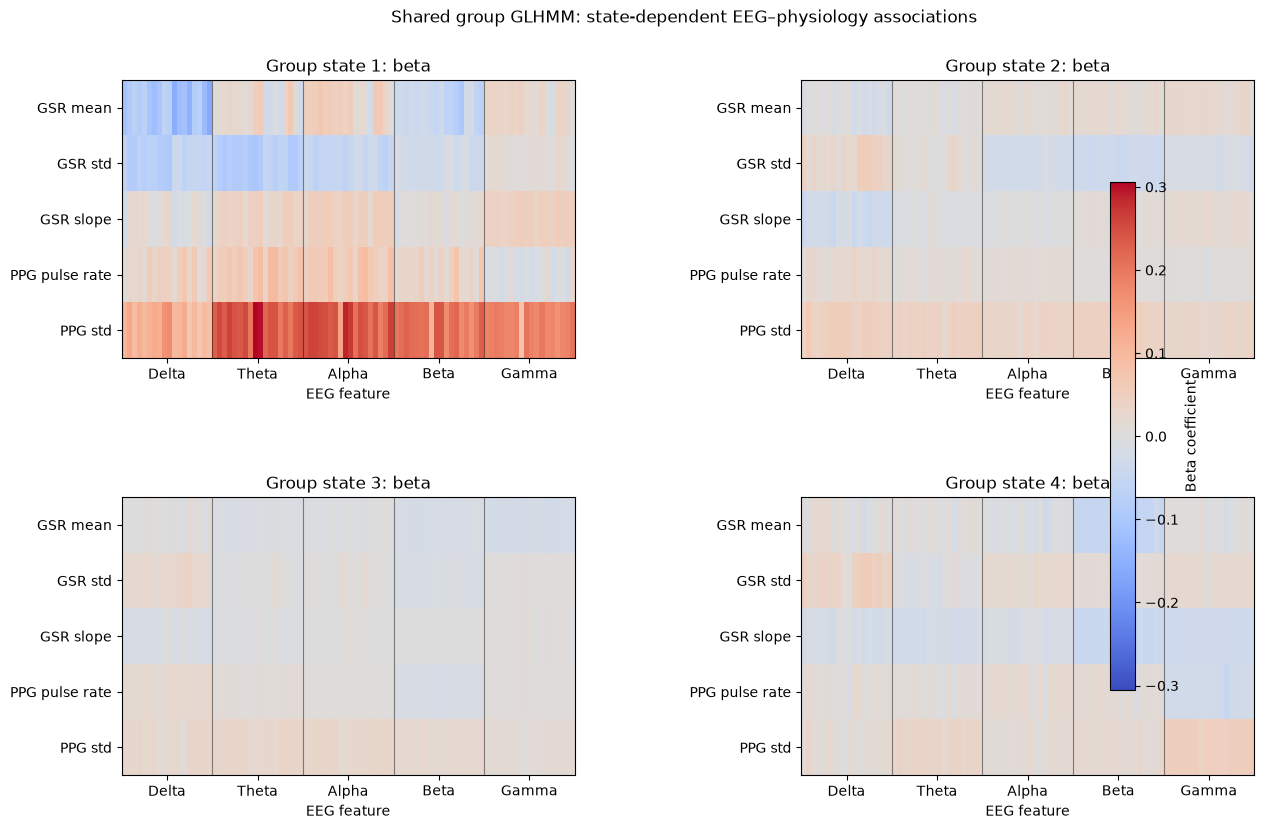

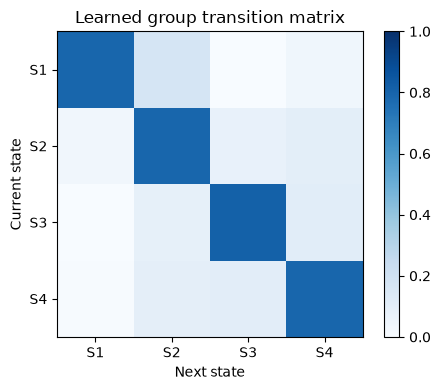

In [75]:
# =========================
# EEG MEANS AND VARIANCES
# =========================

state_means = np.column_stack([hmm.get_mean(k) for k in range(K)])
state_variances = np.column_stack([
    np.diag(hmm.get_covariance_matrix(k=k)) for k in range(K)
])

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

im0 = axes[0].imshow(state_means, aspect="auto", cmap="coolwarm")
axes[0].set_title("Shared state EEG means")
axes[0].set_ylabel("EEG feature")
axes[0].set_xticks(np.arange(K), np.arange(1, K + 1))
axes[0].set_xlabel("Group state")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(state_variances, aspect="auto", cmap="viridis")
axes[1].set_title("Shared state EEG variances (diag)")
axes[1].set_xticks(np.arange(K), np.arange(1, K + 1))
axes[1].set_xlabel("Group state")
fig.colorbar(im1, ax=axes[1], fraction=0.046)

fig.tight_layout()
plt.show()

# =========================
# PHYSIOLOGY -> EEG BETAS
# =========================

phys_names = ["GSR mean", "GSR std", "GSR slope", "PPG pulse rate", "PPG std"]
max_abs_beta = float(np.max(np.abs(betas)))
max_abs_beta = max(max_abs_beta, 1e-12)

ncols = min(K, 2)
nrows = int(np.ceil(K / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.4 * nrows), squeeze=False)

for k in range(K):
    ax = axes.flat[k]
    im = ax.imshow(
        betas[:, :, k], aspect="auto", cmap="coolwarm",
        vmin=-max_abs_beta, vmax=max_abs_beta
    )
    ax.set_yticks(np.arange(5), phys_names)
    ax.set_xlabel("EEG feature")
    ax.set_title(f"Group state {k + 1}: beta")

    if q_eeg == 90:
        band_names = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]
        ax.set_xticks(np.arange(5) * 18 + 8.5, band_names)
        for separator in (17.5, 35.5, 53.5, 71.5):
            ax.axvline(separator, color="black", alpha=0.45, linewidth=0.8)

for ax in axes.flat[K:]:
    ax.axis("off")

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.75, label="Beta coefficient")
fig.suptitle("Shared group GLHMM: state-dependent EEG–physiology associations")
fig.subplots_adjust(top=0.90, right=0.88, hspace=0.5, wspace=0.5)
plt.show()

# One overall state transition matrix is learned from all training subjects.
if hasattr(hmm, "P"):
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(hmm.P, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(K), [f"S{i + 1}" for i in range(K)])
    ax.set_yticks(range(K), [f"S{i + 1}" for i in range(K)])
    ax.set_xlabel("Next state")
    ax.set_ylabel("Current state")
    ax.set_title("Learned group transition matrix")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    plt.show()


# Try to analyze based-on behavior score

**Step A: Load behavioral ratings from every subject**

In [90]:
behavior_rows = []

for file_path in subject_files:

    subject_id = subject_id_from_path(file_path)

    with np.load(file_path) as data:

        VAD = data["VAD"][:, 0, :]
        Emotion = data["Emotion"][:, 0, :]
        PANAS = data["PANAS"][:, 0, :]

        indices = data["indices"]
        video_ids = data["video_ids"].ravel()

    # =========================
    # EXTRACT TRIAL VIDEO IDS
    # =========================

    trial_video_ids = []

    for start, end in indices:

        ids = np.unique(video_ids[start:end])
        assert len(ids) == 1, "Multiple video IDs in one trial"
        trial_video_ids.append(int(ids[0]))

    trial_video_ids = np.array(trial_video_ids)

    # =========================
    # ORGANIZE BEHAVIOR
    # =========================

    assert len(trial_video_ids) == len(VAD) == len(Emotion) == len(PANAS) == 32
    for trial_idx in range(32):
        vid = trial_video_ids[trial_idx]
        row = {
            "subject_id": subject_id,
            "trial_index": trial_idx,
            "video_id": vid,

            # VAD
            "Valence": VAD[trial_idx, 0],
            "Arousal": VAD[trial_idx, 1],
            "Dominance": VAD[trial_idx, 2],

            # Emotion
            "Amusement": Emotion[trial_idx, 0],
            "Disgust": Emotion[trial_idx, 1],
        }

        # PANAS: 10 items
        for i in range(10):
            row[f"PANAS_{i+1}"] = PANAS[trial_idx, i]
        behavior_rows.append(row)

# =========================
# CREATE DATAFRAME
# =========================

behavior_df = pd.DataFrame(behavior_rows)
behavior_df["Coactivation"] = np.minimum(
    behavior_df["Amusement"],
    behavior_df["Disgust"]
)
print("Behavior shape:", behavior_df.shape)
display(behavior_df.head())

Behavior shape: (2272, 19)


,subject_id,trial_index,video_id,Valence,Arousal,Dominance,Amusement,Disgust,PANAS_1,PANAS_2,PANAS_3,PANAS_4,PANAS_5,PANAS_6,PANAS_7,PANAS_8,PANAS_9,PANAS_10,Coactivation
0,1,0,0,5,6,7,2,1,1,1,1,3,1,1,1,1,1,1,1
1,1,1,1,7,7,7,3,1,1,1,3,2,1,1,1,1,1,1,1
2,1,2,2,6,7,7,3,1,1,1,3,1,1,1,1,1,1,1,1
3,1,3,3,4,6,7,2,1,1,1,2,2,1,1,1,1,1,1,1
4,1,4,4,3,5,7,2,1,1,1,2,1,1,1,1,1,1,1,1


**Step B: Merge the behavioral data with GLHMM metrics**

In [91]:
df = trial_df.merge(
    behavior_df,
    on=["subject_id", "trial_index", "video_id"],
    how="left",
    validate="many_to_one"
)

print("Merged data:", df.shape)
display(df.head())
display(df.columns)

Merged data: (9088, 27)


,subject_id,trial_index,video_id,emotion,state,n_samples,FO,SR,LTmean_s,LTmed_s,...,PANAS_2,PANAS_3,PANAS_4,PANAS_5,PANAS_6,PANAS_7,PANAS_8,PANAS_9,PANAS_10,Coactivation
0,1,0,0,Positive,1,14,1.418641e-01,3.055472e-01,0.5,0.5,...,1,1,3,1,1,1,1,1,1,1
1,1,0,0,Positive,2,14,5.629691e-01,6.153783e-01,0.8,1.0,...,1,1,3,1,1,1,1,1,1,1
2,1,0,0,Positive,3,14,2.801639e-11,6.034300e-11,0.0,0.0,...,1,1,3,1,1,1,1,1,1,1
3,1,0,0,Positive,4,14,2.951668e-01,3.098374e-01,1.0,1.0,...,1,1,3,1,1,1,1,1,1,1
4,1,1,1,Positive,1,23,8.577127e-02,1.793248e-01,0.5,0.5,...,1,3,2,1,1,1,1,1,1,1


Index(['subject_id', 'trial_index', 'video_id', 'emotion', 'state',
       'n_samples', 'FO', 'SR', 'LTmean_s', 'LTmed_s', 'LTmax_s', 'Valence',
       'Arousal', 'Dominance', 'Amusement', 'Disgust', 'PANAS_1', 'PANAS_2',
       'PANAS_3', 'PANAS_4', 'PANAS_5', 'PANAS_6', 'PANAS_7', 'PANAS_8',
       'PANAS_9', 'PANAS_10', 'Coactivation'],
      dtype='str')

**Step C: Calculate FO, SR, and lifetime by rating group and plot**

In [ ]:
# =========================
# SETTINGS
# =========================

rating_name = "Arousal"

# None = use all 32 videos
# "Positive", "Negative", "Mixed", None = restrict video category
stimulus_condition = None

# =========================
# SELECT TRIALS
# =========================

rating_df = behavior_df.copy()

if stimulus_condition is not None:

    rating_df["stimulus_emotion"] = rating_df["video_id"].apply(
        lambda vid:
        "Positive" if vid < 8 else
        "Negative" if vid < 16 else
        "Mixed"
    )

    rating_df = rating_df[
        rating_df["stimulus_emotion"] == stimulus_condition
    ].copy()

# =========================
# WITHIN-SUBJECT MEDIAN
# =========================

subject_median = rating_df.groupby(
    "subject_id"
)[rating_name].transform("median")

rating_df["rating_group"] = np.where(
    rating_df[rating_name] > subject_median,
    "High",
    np.where(
        rating_df[rating_name] < subject_median,
        "Low",
        "Middle"
    )
)

# Exclude trials exactly equal to the median
rating_df = rating_df[
    rating_df["rating_group"].isin(["High", "Low"])
]

print(rating_df["rating_group"].value_counts())


rating_metrics = trial_df.merge(
    rating_df[
        ["subject_id", "video_id", "rating_group"]
    ],
    on=["subject_id", "video_id"],
    how="inner"
)

# Average trials within subject and rating group
subject_rating_metrics = (
    rating_metrics.groupby(
        ["subject_id", "state", "rating_group"],
        as_index=False
    )[["FO", "SR", "LTmean_s"]]
    .mean()
)

display(subject_rating_metrics.head())

rating_group
High    177
Low      95
Name: count, dtype: int64


,subject_id,state,rating_group,FO,SR,LTmean_s
0,1,1,High,0.022501,0.022727,0.250000
1,1,2,High,0.401558,0.320209,1.052083
2,1,3,High,0.037264,0.079133,0.250000
3,1,4,High,0.538677,0.326441,1.708333
4,6,1,High,0.076122,0.101389,0.566667


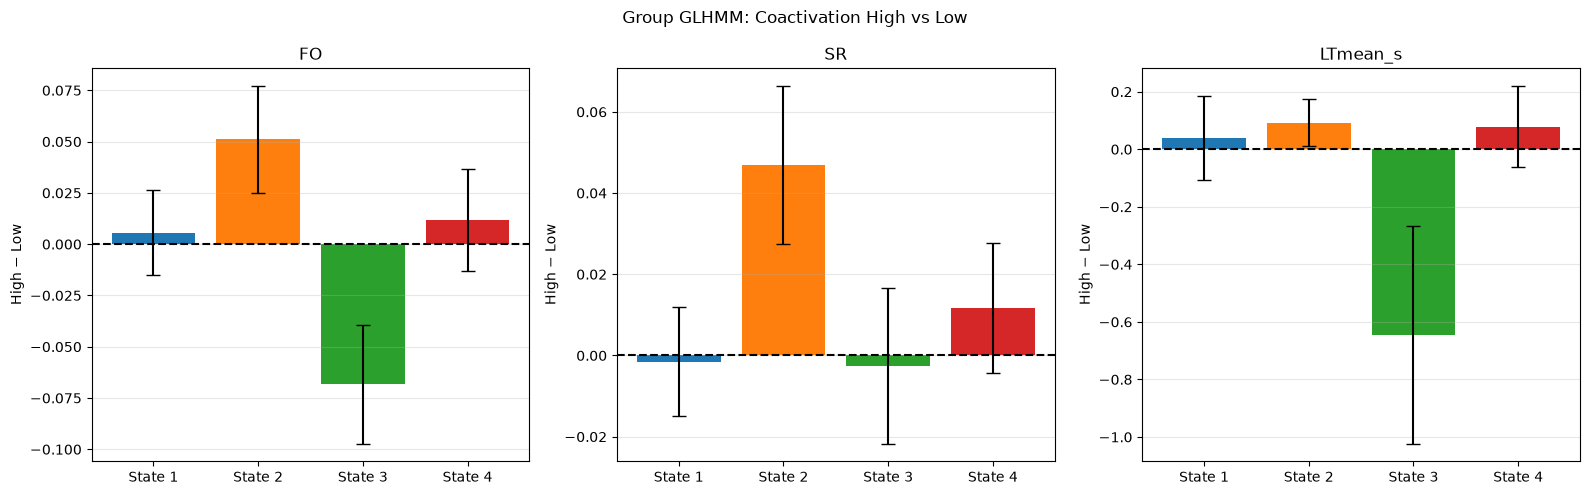

,Metric,State,N_subjects,Mean_High_minus_Low,p_uncorrected
0,FO,1,14,0.005488,0.903198
1,FO,2,14,0.051159,0.078491
2,FO,3,14,-0.068379,0.057983
3,FO,4,14,0.011732,0.426270
4,SR,1,14,-0.001487,0.714844
5,SR,2,14,0.046979,0.041870
6,SR,3,14,-0.002481,0.951538
7,SR,4,14,0.011730,0.714844
8,LTmean_s,1,14,0.039945,0.951538
9,LTmean_s,2,14,0.093005,0.216553


In [100]:
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

metrics = ["FO", "SR", "LTmean_s"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

results = []

for ax, metric in zip(axes, metrics):

    for k in range(1, K + 1):

        state_data = subject_rating_metrics[
            subject_rating_metrics["state"] == k
        ]

        wide = state_data.pivot(
            index="subject_id",
            columns="rating_group",
            values=metric
        )

        if not {"High", "Low"}.issubset(wide.columns):
            continue

        # Keep subjects with both ratings
        wide = wide[["High", "Low"]].dropna()

        difference = (
            wide["High"] - wide["Low"]
        ).to_numpy()
        

        if len(difference) == 0:
            continue

        mean_diff = np.mean(difference)

        if len(difference) > 1:
            sem = np.std(difference, ddof=1) / np.sqrt(len(difference))
        else:
            sem = np.nan

        ax.bar(
            k,
            mean_diff,
            yerr=sem,
            capsize=5
        )

        if len(difference) >= 3 and np.any(difference != 0):
            p_value = wilcoxon(difference).pvalue
        else:
            p_value = np.nan

        results.append({
            "Metric": metric,
            "State": k,
            "N_subjects": len(difference),
            "Mean_High_minus_Low": mean_diff,
            "p_uncorrected": p_value
        })

    ax.axhline(
        0,
        color="black",
        linestyle="--"
    )

    ax.set_xticks(
        range(1, K+1),
        [f"State {k}" for k in range(1, K+1)]
    )

    ax.set_title(metric)
    ax.set_ylabel("High − Low")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    f"Group GLHMM: {rating_name} High vs Low"
)

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)
display(results_df)

## 9. Interpretation checklist

1. **QC:** Check `subject_qc.csv` for the 32 trials, posterior sum error, and state usage. Missing subjects (71 rather than 73) should be documented.
2. **Primary analysis:** Use `subject_emotion_metrics.csv` and the subject-level FO, SR, and lifetime plots, rather than treating thousands of windows as independent observations.
3. **Emotion balance:** Positive and Negative contain 8 videos each, Mixed contains 16. This notebook averages at the **subject × emotion** level so Mixed does not automatically count twice as much.
4. **State semantics:** The same group model gives consistent state labels across subjects. Results are not directly comparable with independently trained subject-specific or band-specific states without alignment.
5. **Trial boundaries:** All 32 original intervals are passed to every decode call, so there are no transitions between unrelated videos.
6. **Features:** The first valid feature is at approximately 8 s **from the start of the common end-aligned/trimmed segment**, reflecting your 8-s PPG window. It is not necessarily 8 s from the original video onset. The temporal sampling interval remains `step=1` s.
7. **Statistical cautions:** The tests are exploratory. Subject-level pairing is appropriate, but video characteristics are associated with emotion classes; a subject-held-out evaluation is still needed for generalization.
8. **Beta:** A group GLHMM beta heatmap visualizes the model's state-dependent EEG–physiology associations. To test beta differences across subjects or emotions, a separate estimation procedure is required; the single fitted beta matrix cannot be treated as 71 independent estimates.

Saved results are under `Group_Analysis/`, and the optional per-subject state-probability caches are under `Subject_Results/` inside the group model directory.
